# Build a Tiny LLM from Scratch

In this notebook we build a small GPT-style language model, one piece at a time, and train it to write text that looks like Shakespeare.

**What you'll see along the way**

| Step | What happens | Big idea |
|---|---|---|
| 1–2 | Set up and load text | An LLM learns only from raw text |
| 3 | Build a tokenizer | Text must become numbers |
| 4–6 | Make training examples | The whole task is *"guess the next token"* |
| 7–8 | A first, very dumb model | An LLM is just a **classifier** over its vocabulary |
| 9–11 | Add **attention** | Tokens look back at earlier tokens for context |
| 12–14 | Train a tiny GPT and generate text | Same recipe as the big models, just much smaller |

**How to use it:** run the cells from top to bottom (Shift + Enter runs one cell). Read the text cell above each code cell first.

**Time:** the whole notebook runs in about 5–10 minutes on an ordinary laptop. No GPU needed.

> **If you know CNNs:** much of this will feel familiar. Data in, predictions out, cross-entropy loss, backpropagation, an optimizer. The only truly new part is attention, in step 9.

## Step 1: Setup

We use **PyTorch**, the same library you'd use to build a CNN.

- `torch` holds the tensors (multi-dimensional arrays) and does the math.
- `nn` has the building blocks for neural networks (layers).
- `F` has handy functions like `softmax` and `cross_entropy`.

If PyTorch isn't installed, remove the `#` in front of `%pip install ...`, run the cell once, then restart the notebook.

`torch.manual_seed(42)` makes the random numbers repeatable, so you get the same results each time you run it.

In [1]:
# %pip install torch matplotlib

import os
import urllib.request

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Use a GPU if there is one, otherwise the CPU (which is fine for this notebook)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Running on:", device)

PyTorch version: 2.11.0
Running on: cpu


## Step 2: Get some text to learn from

A language model learns entirely from examples of text. Big models read trillions of words from the internet. We'll use **"Tiny Shakespeare"**: about 1 million characters of Shakespeare's plays in a single text file.

This cell downloads the file once and saves it as `input.txt` next to the notebook. (If the download is blocked, open the URL in your browser, save the page as `input.txt` in the same folder as this notebook, and run the cell again.)

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(url, "input.txt")

with open("input.txt", encoding="utf-8") as f:
    text = f.read()

print("Number of characters:", len(text))
print()
print(text[:500])   # show the first 500 characters

Number of characters: 1115394

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## Step 3: Build a tokenizer (text → numbers)

A neural network only works with numbers. A photo is *already* numbers (pixel values), but text isn't, so we need a **tokenizer** to convert it.

Real LLMs use subword tokens (pieces like `"un"`, `"happ"`, `"y"`) and vocabularies of 50,000–200,000. We'll use the simplest possible tokenizer: **every single character is one token.**

1. Find every unique character in the text. That list is our **vocabulary**, and its length is the **vocabulary size**.
2. Give each character an ID number: `stoi` ("string to integer").
3. Make the reverse lookup: `itos` ("integer to string").
4. `encode` turns text into a list of IDs; `decode` turns IDs back into text.

Notice the IDs are arbitrary labels: the number 46 isn't "closer in meaning" to 47. The model will learn what each token means later.

In [3]:
chars = sorted(set(text))      # every unique character, in sorted order
vocab_size = len(chars)

print("Our vocabulary:", repr("".join(chars)))
print("Vocabulary size:", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}   # character -> ID
itos = {i: ch for i, ch in enumerate(chars)}   # ID -> character

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[i] for i in ids)

print()
print("encode('hello') =", encode("hello"))
print("decode(encode('hello')) =", decode(encode("hello")))

Our vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Vocabulary size: 65

encode('hello') = [46, 43, 50, 50, 53]
decode(encode('hello')) = hello


## Step 4: Turn the whole text into numbers and split it

We encode the entire text into one long tensor of IDs.

Then we split it like any machine-learning dataset:

- **Training data (first 90%)**: what the model learns from.
- **Validation data (last 10%)**: text the model never trains on. We use it to check whether the model has really learned Shakespeare-like patterns, or just memorized.

In [4]:
data = torch.tensor(encode(text), dtype=torch.long)
print("Data shape:", data.shape)
print("First 20 IDs:", data[:20].tolist())

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

Data shape: torch.Size([1115394])
First 20 IDs: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]
Training characters: 1003854
Validation characters: 111540


## Step 5: What does "guess the next token" actually mean?

This is the most important idea in the notebook.

We don't need labels like we do for image classification. **The text labels itself:** for every position, the "correct answer" is simply the character that comes next.

Take a short chunk of 9 characters. It gives us **8 training examples** at once. The model sees the context on the left and must predict the character on the right. The context can be as short as 1 character or as long as the whole chunk.

The maximum context length is called the **context size** (or block size). Here we use 8 just to print a demo; later we'll use 64.

In [5]:
demo_size = 8
x = train_data[:demo_size]          # the input
y = train_data[1:demo_size + 1]     # the same text shifted one step left = the answers

for t in range(demo_size):
    context = x[:t + 1]
    target = y[t]
    print(f"context: {decode(context.tolist())!r:14}  -->  next character: {decode([target.item()])!r}")

context: 'F'             -->  next character: 'i'
context: 'Fi'            -->  next character: 'r'
context: 'Fir'           -->  next character: 's'
context: 'Firs'          -->  next character: 't'
context: 'First'         -->  next character: ' '
context: 'First '        -->  next character: 'C'
context: 'First C'       -->  next character: 'i'
context: 'First Ci'      -->  next character: 't'


## Step 6: Make batches

Just like training a CNN on a batch of images at once, we train on a **batch** of text chunks at once, because it's faster.

`get_batch` picks random starting spots in the text and cuts out chunks:

- `x` has shape **(batch_size, context_size)**: the inputs.
- `y` has the same shape: the same chunks shifted by one character, i.e. the answers for every position.

Below we print a tiny batch of 4 chunks, 8 characters each. Compare `x` and `y`: each row of `y` is its row of `x` moved one step to the left.

In [6]:
def get_batch(split, batch_size, context_size):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - context_size, (batch_size,))
    x = torch.stack([source[i : i + context_size] for i in starts])
    y = torch.stack([source[i + 1 : i + context_size + 1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train", batch_size=4, context_size=8)
print("inputs x:\n", xb)
print("answers y:\n", yb)
print()
print("First row as text:  x =", repr(decode(xb[0].tolist())), "  y =", repr(decode(yb[0].tolist())))

inputs x:
 tensor([[57,  1, 46, 47, 57,  1, 50, 53],
        [ 1, 58, 46, 43, 56, 43,  1, 41],
        [17, 26, 15, 17, 10,  0, 32, 53],
        [57, 58,  6,  1, 61, 47, 58, 46]])
answers y:
 tensor([[ 1, 46, 47, 57,  1, 50, 53, 60],
        [58, 46, 43, 56, 43,  1, 41, 39],
        [26, 15, 17, 10,  0, 32, 53,  1],
        [58,  6,  1, 61, 47, 58, 46,  0]])

First row as text:  x = 's his lo'   y = ' his lov'


## Step 7: Our first model, the "bigram" model

Let's start with the simplest model that could possibly work. It predicts the next character by looking **only at the current character**, with no memory of anything earlier.

It's just one lookup table with one row per character. Each row holds `vocab_size` scores, one for every possible next character. (Inside the model, `nn.Embedding` is simply a learnable lookup table.)

**This is a classifier.** Like a CNN that outputs a score for each class (cat, dog, car…), this model outputs a score for each of the 65 characters: *"which character comes next?"* The scores are called **logits**. A real LLM does exactly the same thing, just with ~100,000 classes and a far smarter network in between.

The **loss** is the same **cross-entropy** used for image classification: it's low when the model gives the correct next character a high probability.

In [7]:
class BigramModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # One row per character; each row = scores for every possible next character
        self.table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.table(idx)              # shape: (batch, time, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            # cross_entropy wants a flat list of predictions and a flat list of answers
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

### Generating text

To write text, the model works in a loop, one character at a time:

1. Feed in the text so far.
2. Take the scores for the **last** position and turn them into probabilities with **softmax**.
3. **Randomly pick** the next character according to those probabilities (more likely characters get picked more often).
4. Add it to the text and go back to step 1.

That's all an LLM is doing when it "writes": predict, pick, append, repeat.

In [8]:
@torch.no_grad()   # no learning happens while generating, so skip gradient bookkeeping
def generate(model, max_new_chars, context_size, start="\n"):
    model.eval()
    idx = torch.tensor([encode(start)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        idx_cond = idx[:, -context_size:]          # keep only the last context_size characters
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]                   # scores for the last position only
        probs = F.softmax(logits, dim=-1)           # scores -> probabilities
        next_id = torch.multinomial(probs, num_samples=1)   # pick one at random
        idx = torch.cat([idx, next_id], dim=1)      # append and repeat
    model.train()
    return decode(idx[0].tolist())

Let's test the bigram model **before any training**. Its table is random, so expect total gibberish.

Also look at the starting loss. If the model is guessing randomly among 65 characters, the loss should be about ln(65) ≈ **4.17**. That's our "knows nothing" baseline.

In [9]:
bigram = BigramModel(vocab_size).to(device)

xb, yb = get_batch("train", batch_size=32, context_size=8)
_, loss = bigram(xb, yb)
print(f"Loss before training: {loss.item():.2f}   (random guessing would be about 4.17)")
print()
print(generate(bigram, max_new_chars=200, context_size=8))

Loss before training: 4.65   (random guessing would be about 4.17)


I$zF
BMYCy:cUDB EHmVJG; SHYtjuWoxSSePwUZC$NFpzMrhrX'RSYJDvqzXRNAr!m
KlW $ mlYeFQaEB!g:iHYrxhF
uyQaaRVlrFApsyNUTss
GDlzO-RfDtKDKmSVsjfhf
pmNHwb3ViNqpx
s.GULhrvPgPKC-FxBbHtNcfD-M!qp ;boRUQmSp?gPTsNA3?D!


## Step 8: Train it

The training loop is the same one you'd write for a CNN:

1. Get a batch.
2. Run the model and compute the loss.
3. `loss.backward()` computes how to nudge every number in the model to lower the loss (backpropagation).
4. `optimizer.step()` makes the nudge. (**AdamW** is a popular optimizer.)

Every so often we check the average loss on both the training and validation data (`estimate_loss`) so we can watch progress.

We write the loop once as a function and reuse it later for the real GPT.

In [10]:
@torch.no_grad()
def estimate_loss(model, batch_size, context_size, eval_batches=50):
    model.eval()
    result = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_batches)
        for k in range(eval_batches):
            x, y = get_batch(split, batch_size, context_size)
            _, loss = model(x, y)
            losses[k] = loss.item()
        result[split] = losses.mean().item()
    model.train()
    return result


def train(model, steps, batch_size, context_size, learning_rate, report_every):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = []
    for step in range(steps):
        # Check progress every so often
        if step % report_every == 0 or step == steps - 1:
            losses = estimate_loss(model, batch_size, context_size)
            history.append((step, losses["train"], losses["val"]))
            print(f"step {step:5d}:  train loss {losses['train']:.3f}   val loss {losses['val']:.3f}")

        x, y = get_batch("train", batch_size, context_size)   # 1. get a batch
        _, loss = model(x, y)                                  # 2. predict + measure error
        optimizer.zero_grad(set_to_none=True)
        loss.backward()                                        # 3. backpropagation
        optimizer.step()                                       # 4. update the weights
    return history

In [11]:
bigram_history = train(bigram, steps=3000, batch_size=32, context_size=8,
                       learning_rate=1e-2, report_every=500)

step     0:  train loss 4.680   val loss 4.677
step   500:  train loss 2.582   val loss 2.603
step  1000:  train loss 2.487   val loss 2.515
step  1500:  train loss 2.477   val loss 2.502
step  2000:  train loss 2.466   val loss 2.486
step  2500:  train loss 2.452   val loss 2.491
step  2999:  train loss 2.463   val loss 2.481


The loss should drop from about 4.2 to about **2.5**. Let's see what it writes now.

You'll notice it has learned a few things: common letter pairs, spaces between word-like chunks, capital letters after line breaks. But it still isn't writing words, because **it only ever sees one character of context.** After `"q"` it can guess `"u"`, but after `" "` it has no idea what word it's in the middle of.

In [12]:
print(generate(bigram, max_new_chars=300, context_size=8))


Inoveey,


OR thino t e
IIDULI pl ar.
Hillyo br thofeaighrenoonche d ik.

Whed heg' ous dove GI beay nd t t yowacfanome ce:
Sus
ABot th, thereamu Be; l, the, igis at'logrool d benowethat hathetheth alotoil se: l.


Ho fre ONeoulad araprwe

Heng thorore angherman
SLI torntshit ben w avenowhin ay; ale


## Step 9: The key idea, attention

To do better, each position needs to **look back at the characters before it.** That's what **attention** does.

**Analogy with CNNs:** a convolution mixes each pixel with its *neighbors*. Attention mixes each token with *earlier tokens*, any of them, not just neighbors, and the model learns **how much to pay attention to each one.**

There's one rule: **a token may look only at the past, never the future.** Otherwise it could cheat by peeking at the very answer it's supposed to predict.

### The simplest version: average the past

Imagine 4 positions. A simple way to give each position some context is to let it take the **average** of itself and everything before it. We can write that as a table of **weights** (each row adds up to 1):

- Row 1: position 1 can only see itself.
- Row 4: position 4 sees positions 1–4 equally (25% each).
- The zeros above the diagonal block the future.

The trick to building that table: start with a score for every pair, set the future ones to −infinity, then apply **softmax**. Softmax turns −infinity into exactly 0, and turns the rest into weights that add up to 1.

In [13]:
T = 4
scores = torch.zeros(T, T)                       # every pair gets the same score
mask = torch.tril(torch.ones(T, T))              # 1s on and below the diagonal = "the past"
scores = scores.masked_fill(mask == 0, float("-inf"))   # block the future
weights = F.softmax(scores, dim=-1)

print("Mask (1 = allowed to look):\n", mask)
print()
print("Attention weights (each row adds up to 1):\n", weights)

Mask (1 = allowed to look):
 tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])

Attention weights (each row adds up to 1):
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500]])


### Real attention: the model decides the scores

Averaging everything equally is too simple. In *"the cat sat because **it** was tired"*, the word "it" should pay a lot of attention to "cat" and little to "the".

So in real attention the scores aren't all zero. Each token produces three vectors through small learned layers:

- **Query**: "What am I looking for?"
- **Key**: "What do I contain?"
- **Value**: "What will I share if someone pays attention to me?"

The score between two tokens = how well one token's **query** matches the other's **key** (a dot product). After masking and softmax, each token collects a weighted mix of the **values** of earlier tokens.

Below, we fake some scores with random numbers just to see what uneven attention weights look like. Notice the rows still add up to 1 and the future is still blocked.

In [14]:
scores = torch.randn(T, T)                       # pretend these came from query·key
scores = scores.masked_fill(mask == 0, float("-inf"))
weights = F.softmax(scores, dim=-1)
print(weights.round(decimals=2))

tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.6400, 0.3600, 0.0000, 0.0000],
        [0.4400, 0.3500, 0.2000, 0.0000],
        [0.1100, 0.0700, 0.0700, 0.7400]])


## Step 10: Code one attention "head"

Here is the real thing. It's exactly the recipe from step 9, in code:

1. Make **keys**, **queries**, and **values** with three small `Linear` layers.
2. **Scores** = queries × keys (we also scale them down by √head_size, which keeps the numbers from getting too large and makes training stable).
3. **Mask** the future and apply **softmax** to get the weights.
4. Output = weights × values.

`register_buffer` just stores the mask inside the model (it isn't something the model learns).

In [15]:
class Head(nn.Module):
    def __init__(self, embed_size, head_size, context_size):
        super().__init__()
        self.key = nn.Linear(embed_size, head_size, bias=False)
        self.query = nn.Linear(embed_size, head_size, bias=False)
        self.value = nn.Linear(embed_size, head_size, bias=False)
        self.register_buffer("mask", torch.tril(torch.ones(context_size, context_size)))

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)        # what each token contains
        q = self.query(x)      # what each token is looking for
        v = self.value(x)      # what each token will share

        scores = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)        # how well each query matches each key
        scores = scores.masked_fill(self.mask[:T, :T] == 0, float("-inf"))  # no peeking at the future
        weights = F.softmax(scores, dim=-1)                              # each row sums to 1
        return weights @ v                                               # weighted mix of values

## Step 11: Assemble the full tiny GPT

Now we put the pieces together. Each part has a simple job:

- **Token embedding**: turns each character ID into a vector of numbers (`embed_size` long). These vectors are learned, so characters that behave similarly end up with similar vectors. Think of each vector as a "pixel" with many channels.
- **Position embedding**: attention by itself doesn't know the *order* of tokens. So we add a learned vector for "position 0", "position 1", etc.
- **Multi-head attention**: several attention heads run side by side, each free to focus on a different kind of pattern (one might track vowels, another the start of words). Their outputs are joined.
- **Feed-forward**: a small ordinary neural network applied to each position on its own. Attention *gathers* information from other tokens; feed-forward *thinks about* what was gathered.
- **Block**: one attention + one feed-forward. We stack several blocks, like stacking convolution layers in a CNN, so later blocks build on what earlier blocks found.
- **Residual connections** (`x = x + ...`) and **LayerNorm**: two standard tricks that keep deep networks easy to train. You don't need to understand them deeply; just know they help training go smoothly.
- **Output layer**: turns each position's vector into one score per character. The same classifier head as in the bigram model.

In [16]:
class MultiHeadAttention(nn.Module):
    # Several heads in parallel; their outputs are joined side by side
    def __init__(self, embed_size, num_heads, context_size):
        super().__init__()
        head_size = embed_size // num_heads
        self.heads = nn.ModuleList([Head(embed_size, head_size, context_size) for _ in range(num_heads)])
        self.proj = nn.Linear(embed_size, embed_size)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.proj(out)


class FeedForward(nn.Module):
    # A small regular neural network, applied to each position separately
    def __init__(self, embed_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_size, 4 * embed_size),
            nn.ReLU(),
            nn.Linear(4 * embed_size, embed_size),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    # One transformer block: gather info (attention), then process it (feed-forward)
    def __init__(self, embed_size, num_heads, context_size):
        super().__init__()
        self.ln1 = nn.LayerNorm(embed_size)
        self.attention = MultiHeadAttention(embed_size, num_heads, context_size)
        self.ln2 = nn.LayerNorm(embed_size)
        self.feed_forward = FeedForward(embed_size)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))      # residual connection: add, don't replace
        x = x + self.feed_forward(self.ln2(x))
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, embed_size, num_heads, num_layers, context_size):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embed_size)
        self.position_embedding = nn.Embedding(context_size, embed_size)
        self.blocks = nn.Sequential(*[Block(embed_size, num_heads, context_size) for _ in range(num_layers)])
        self.ln_final = nn.LayerNorm(embed_size)
        self.output = nn.Linear(embed_size, vocab_size)   # the classifier head

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding(idx)                                   # (B, T, embed_size)
        pos = self.position_embedding(torch.arange(T, device=idx.device)) # (T, embed_size)
        x = tok + pos                     # each token now knows what it is AND where it is
        x = self.blocks(x)                # attention + feed-forward, several times
        x = self.ln_final(x)
        logits = self.output(x)           # (B, T, vocab_size): a score for every possible next character

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

## Step 12: Create and train the tiny GPT

These **hyperparameters** control the model's size. They're kept small so it trains on a laptop CPU in a few minutes.

| Setting | Value | Meaning |
|---|---|---|
| `context_size` | 64 | How many characters the model can look back at |
| `embed_size` | 64 | Length of each token's vector |
| `num_heads` | 4 | Attention heads per block |
| `num_layers` | 4 | How many blocks are stacked |

For comparison, GPT-3 used a context of 2,048 tokens, vectors 12,288 long, 96 heads, and 96 layers, for 175 **billion** parameters. Ours has about 200 **thousand**. Same design, very different scale.

The next cell only **creates** the model (instant). We'll look at its architecture, then train it.

In [17]:
context_size = 64
embed_size = 64
num_heads = 4
num_layers = 4

model = TinyGPT(vocab_size, embed_size, num_heads, num_layers, context_size).to(device)
num_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {num_params:,} parameters")

Model size: 211,777 parameters


### Look at the architecture

Before training, let's see what we just built. (You don't need to train first: the shapes and parameter counts are fixed by the architecture.) The first cell runs one chunk of text through the model and prints each part's **output shape** and **number of parameters**. The second cell draws the same model as a diagram.

Both read their numbers straight from `model`, so if you change the hyperparameters above and rerun, they update too.

- The **(batch, 64, 64)** shape means: for every one of the 64 characters, a vector of 64 numbers. That shape stays the same through every block.
- Only the **output layer** changes it, to 65 scores per position: one for each character in the vocabulary.
- Almost all the parameters live in the **4 transformer blocks**, and inside each block, the feed-forward network holds about twice as many as attention.

In [18]:
# Run one example through the model and record the output shape of each part
parts = [("Token embedding", model.token_embedding),
         ("Position embedding", model.position_embedding)]
parts += [(f"Block {i + 1}", block) for i, block in enumerate(model.blocks)]
parts += [("Final LayerNorm", model.ln_final),
          ("Output layer", model.output)]

shapes = {}
hooks = [module.register_forward_hook(lambda m, inp, out, name=name: shapes.__setitem__(name, tuple(out.shape)))
         for name, module in parts]

example = torch.zeros(1, context_size, dtype=torch.long, device=device)   # 1 chunk of context_size characters
with torch.no_grad():
    model(example)
for hook in hooks:
    hook.remove()

print(f"{'Part':<20} {'Output shape':<16} {'Parameters':>11}")
print("-" * 49)
for name, module in parts:
    count = sum(p.numel() for p in module.parameters())
    print(f"{name:<20} {str(shapes[name]):<16} {count:>11,}")
print("-" * 49)
print(f"{'Total':<37} {sum(p.numel() for p in model.parameters()):>11,}")

Part                 Output shape      Parameters
-------------------------------------------------
Token embedding      (1, 64, 64)            4,160
Position embedding   (64, 64)               4,096
Block 1              (1, 64, 64)           49,792
Block 2              (1, 64, 64)           49,792
Block 3              (1, 64, 64)           49,792
Block 4              (1, 64, 64)           49,792
Final LayerNorm      (1, 64, 64)              128
Output layer         (1, 64, 65)            4,225
-------------------------------------------------
Total                                     211,777


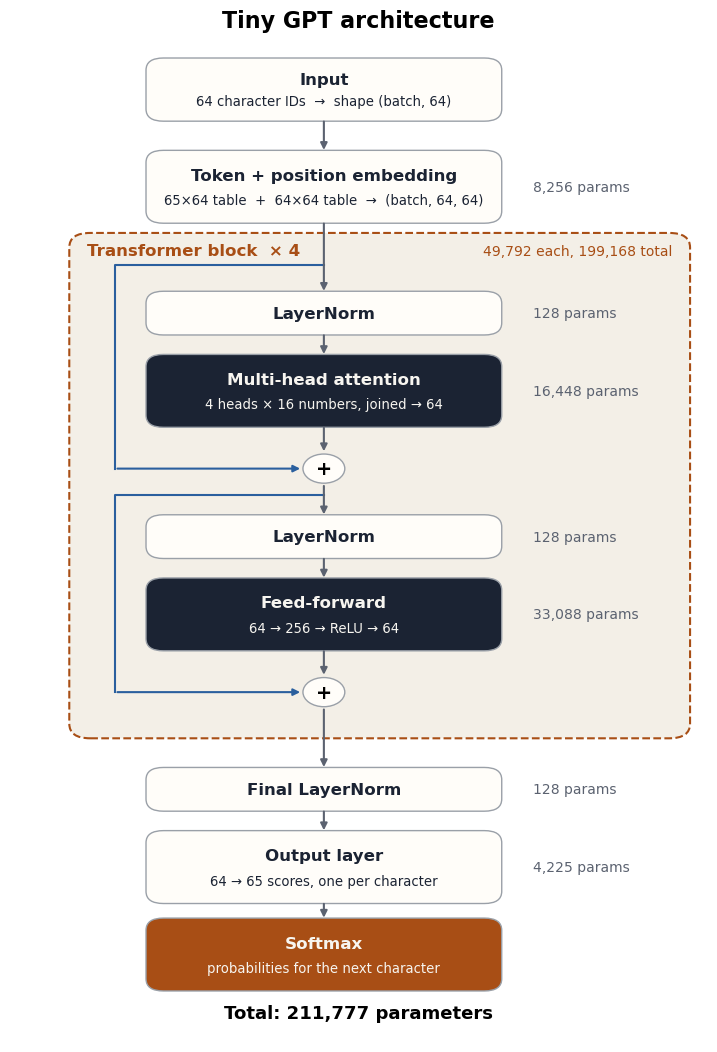

In [19]:
from matplotlib.patches import FancyBboxPatch, Circle

# Read the sizes straight from the model, so the picture always matches the code
vocab, C = model.token_embedding.weight.shape
T = model.position_embedding.weight.shape[0]
block = model.blocks[0]
H = len(block.attention.heads)
hidden = block.feed_forward.net[0].out_features
L = len(model.blocks)

def count(*modules):
    return sum(p.numel() for m in modules for p in m.parameters())

fig, ax = plt.subplots(figsize=(9, 13))
ax.set_xlim(0, 10)
ax.set_ylim(5.4, 26)
ax.axis("off")

def box(y, title, detail, params=None, color="#FFFDF9", text="#1B2333", h=1.4):
    ax.add_patch(FancyBboxPatch((2, y - h / 2), 5, h, boxstyle="round,pad=0.05,rounding_size=0.25",
                                facecolor=color, edgecolor="#9AA0A8", linewidth=1))
    ax.text(4.5, y + h / 6 if detail else y, title, ha="center", va="center", fontsize=12, fontweight="bold", color=text)
    ax.text(4.5, y - h / 5, detail, ha="center", va="center", fontsize=9.5, color=text)
    if params is not None:
        ax.text(7.5, y, f"{params:,} params", ha="left", va="center", fontsize=10, color="#5B6270")
    return y + h / 2, y - h / 2              # top and bottom edges

def add(y):
    ax.add_patch(Circle((4.5, y), 0.3, facecolor="#FFFDF9", edgecolor="#9AA0A8"))
    ax.text(4.5, y, "+", ha="center", va="center", fontsize=14, fontweight="bold")
    return y + 0.3, y - 0.3

def arrow(y_from, y_to):
    ax.annotate("", xy=(4.5, y_to), xytext=(4.5, y_from),
                arrowprops=dict(arrowstyle="-|>", color="#5B6270", lw=1.5))

def skip(y_from, y_to):
    # residual connection: carry x around the layer and add it back in
    ax.plot([4.5, 1.5, 1.5], [y_from, y_from, y_to], color="#2A5F9E", lw=1.5)
    ax.annotate("", xy=(4.2, y_to), xytext=(1.5, y_to),
                arrowprops=dict(arrowstyle="-|>", color="#2A5F9E", lw=1.5))

dark = dict(color="#1B2333", text="#F7F5F0")

# The transformer block (drawn first so it sits behind the boxes)
ax.add_patch(FancyBboxPatch((0.9, 11.7), 8.8, 10.3, boxstyle="round,pad=0.05,rounding_size=0.3",
                            facecolor="#F3EFE7", edgecolor="#A84E15", linestyle="--", linewidth=1.5))
ax.text(1.1, 21.6, f"Transformer block  × {L}", fontsize=12, fontweight="bold", color="#A84E15")
ax.text(9.5, 21.6, f"{count(block):,} each, {count(model.blocks):,} total",
        ha="right", fontsize=10, color="#A84E15")

steps = [
    box(25, "Input", f"{T} character IDs  →  shape (batch, {T})", h=1.2),
    box(23, "Token + position embedding",
        f"{vocab}×{C} table  +  {T}×{C} table  →  (batch, {T}, {C})",
        count(model.token_embedding, model.position_embedding)),
    box(20.4, "LayerNorm", "", count(block.ln1), h=0.8),
    box(18.8, "Multi-head attention", f"{H} heads × {C // H} numbers, joined → {C}",
        count(block.attention), **dark),
    add(17.2),
    box(15.8, "LayerNorm", "", count(block.ln2), h=0.8),
    box(14.2, "Feed-forward", f"{C} → {hidden} → ReLU → {C}", count(block.feed_forward), **dark),
    add(12.6),
    box(10.6, "Final LayerNorm", "", count(model.ln_final), h=0.8),
    box(9.0, "Output layer", f"{C} → {vocab} scores, one per character", count(model.output)),
    box(7.2, "Softmax", "probabilities for the next character", color="#A84E15", text="#F7F5F0"),
]
for (_, bottom), (top, _) in zip(steps, steps[1:]):
    arrow(bottom, top)

skip(21.4, 17.2)   # around attention
skip(16.65, 12.6)  # around feed-forward

ax.text(5, 5.9, f"Total: {count(model):,} parameters", ha="center", fontsize=13, fontweight="bold")
ax.set_title("Tiny GPT architecture", fontsize=16, fontweight="bold", pad=10)
plt.show()

### Train it

Now train the model. It prints progress every 500 steps. **This cell takes a few minutes on a CPU.** Watch the loss fall well below the bigram's ~2.5.

In [20]:
gpt_history = train(model, steps=4000, batch_size=32, context_size=context_size,
                    learning_rate=1e-3, report_every=500)

step     0:  train loss 4.401   val loss 4.399
step   500:  train loss 2.238   val loss 2.257
step  1000:  train loss 1.972   val loss 2.034
step  1500:  train loss 1.825   val loss 1.951
step  2000:  train loss 1.730   val loss 1.872
step  2500:  train loss 1.671   val loss 1.831
step  3000:  train loss 1.621   val loss 1.809
step  3500:  train loss 1.581   val loss 1.766
step  3999:  train loss 1.547   val loss 1.738


### Plot the learning curve

The two lines should fall together. If the **validation** loss stopped falling while the **training** loss kept dropping, the model would be memorizing instead of learning (overfitting), exactly as with a CNN.

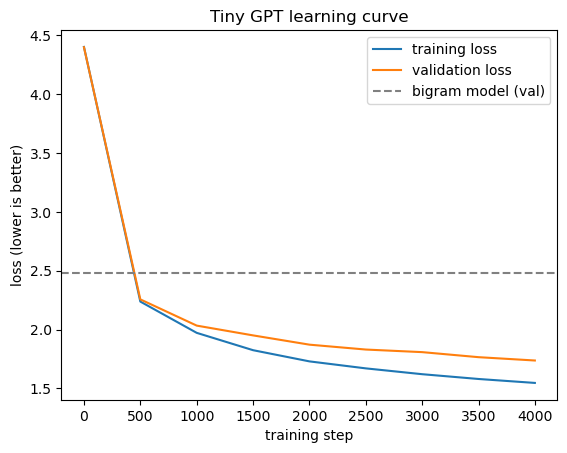

In [21]:
steps = [h[0] for h in gpt_history]
plt.plot(steps, [h[1] for h in gpt_history], label="training loss")
plt.plot(steps, [h[2] for h in gpt_history], label="validation loss")
plt.axhline(bigram_history[-1][2], linestyle="--", color="gray", label="bigram model (val)")
plt.xlabel("training step")
plt.ylabel("loss (lower is better)")
plt.title("Tiny GPT learning curve")
plt.legend()
plt.show()

## Step 13: Let it write

Now generate 500 characters. It won't make real sense (the model is tiny and has read only 1 MB of text), but compare it with the bigram output: you should see real words, character names in capitals followed by colons, line breaks like a script, and a Shakespeare-ish rhythm.

It learned all of that from nothing but **"guess the next character."**

Run the cell several times: the random picking in step 3 of `generate` gives you different text each time.

In [22]:
print(generate(model, max_new_chars=500, context_size=context_size))



CAPULETES:
My lest discity, like our plain, so clauding
We endeed fool his none thy arm that duispll
My hither? let 's counsely he melf doissicct'd commodom.

WARWICht, that the man:
How; gidly Clown:
This tale ungieve done, whose that only;
Say, her this stray loss'd on the own
Mark, fear and your leaven you: what you sheder he towards
As the bodlooks of the shrellort flood,
What drot ful one thee unhon falses nowor thousandly
Up the minder and hence men, fare that new-enviragfath thoughts
Tel


You can also give it a starting prompt. (Use only characters that appear in Shakespeare's text; the tokenizer doesn't know any others.)

In [23]:
print(generate(model, max_new_chars=300, context_size=context_size, start="ROMEO:\n"))

ROMEO:
When nor are not to woe! I had will sLord and friend,
But actickir thing to care my fight.
When ado, acch
While not on book then, been, shait me fousand
That the not hanking welt errely-head that our doth.

MENENIUS:
I buy! O wils; a not of Clarence Cormons their
Of rackious your far oppraiso on; fo


## Step 14: Peek inside the "classifier"

Finally, let's see the model's raw prediction for one step. We give it a prompt and show its top 5 guesses for the next character, with probabilities.

This is the exact moment that every LLM, including the huge ones, repeats over and over: **a probability for every token in the vocabulary.** The generator then picks one.

In [24]:
@torch.no_grad()
def show_next_char_guesses(model, prompt, top_k=5):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)[:, -context_size:]
    logits, _ = model(idx)
    probs = F.softmax(logits[0, -1], dim=-1)
    top = torch.topk(probs, top_k)
    print(f"Prompt: {prompt!r}")
    for p, i in zip(top.values, top.indices):
        print(f"   next = {itos[i.item()]!r:6}  probability {p.item():.1%}")
    model.train()

show_next_char_guesses(model, "To be, or not to b")
print()
show_next_char_guesses(model, "KING HENR")

Prompt: 'To be, or not to b'
   next = 'e'     probability 67.4%
   next = 'r'     probability 8.7%
   next = 'y'     probability 5.4%
   next = 'l'     probability 4.8%
   next = 'u'     probability 4.5%

Prompt: 'KING HENR'
   next = 'Y'     probability 99.2%
   next = 'E'     probability 0.4%
   next = 'O'     probability 0.1%
   next = 'U'     probability 0.1%
   next = 'I'     probability 0.0%


## Summary: how this connects to real LLMs

| Our tiny GPT | A real LLM (like GPT-4 or Claude) |
|---|---|
| 1 MB of Shakespeare | Trillions of tokens from the web, books, code |
| 1 character = 1 token, vocabulary of 65 | Subword tokens, vocabulary of ~100,000+ |
| Context of 64 characters | Context of hundreds of thousands of tokens |
| ~200 thousand parameters | Hundreds of billions of parameters |
| Minutes on a laptop | Months on thousands of GPUs |
| Only "predict the next token" | The same pre-training, plus extra training to follow instructions and be helpful |

The core recipe is identical: **tokenize → embed → attention + feed-forward blocks → score every token → pick one → repeat.**

### Things to try

- **Make it bigger:** set `num_layers = 6` and `embed_size = 128` and retrain (slower, but better text).
- **Longer memory:** set `context_size = 128`.
- **Train longer:** change `steps=4000` to `steps=10000`.
- **Your own text:** replace `input.txt` with any large text file you like (a novel from Project Gutenberg works well), then run everything again.
- **Remove attention:** in `Block.forward`, comment out the attention line and retrain. Watch how much worse it gets. That shows you what attention contributes.